In [1]:
import numpy as np
import matplotlib.pyplot as plt

## Week 2.1

9.761194029850746
cloud base height: 280.280 m


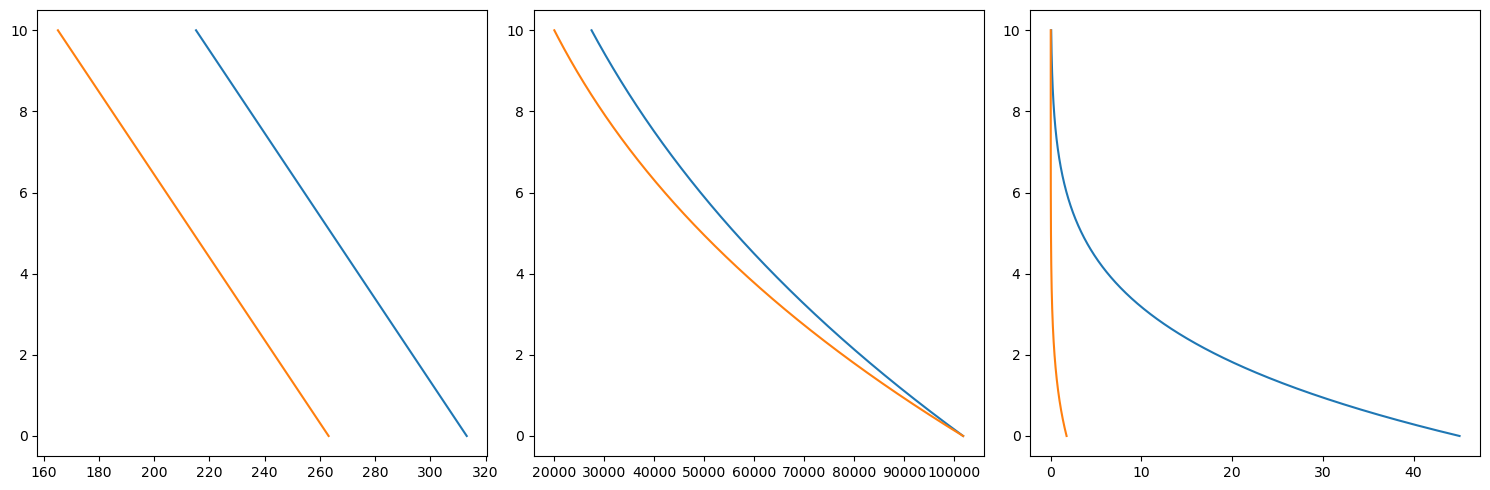

In [44]:
p_sfc = 101800 #Pa
T_sfc = 273.16 + 30 # K
RH = 0.8 # - 
g = 9.81 * 1000 # km / s^2
cp = 1005 # idk
print(g/cp)

Rd = 287.05
Rv = 461.5

lapse_rate = -9.8
z = np.linspace(0,10,int(1e3))

def Tz(T_sfc = T_sfc,lapse_rate = lapse_rate,z = z):
    return T_sfc + lapse_rate * z
T_z = Tz()

def pz(p_sfc = p_sfc, lapse_rate = lapse_rate, z=z, T_sfc = T_sfc):
    return p_sfc * (1+(lapse_rate * z) / T_sfc) ** (-g / (lapse_rate * Rd))
p_z = pz()

def e_sat(T_z=T_z):
    return 610.78 * np.exp((17.2694*(T_z-273.16)) / (T_z - 35.86))
e_SAT = e_sat()

q_sat =(Rd / Rv) * (e_SAT / p_z)

T_sfc_array = 273.16 + np.array([40,-10])

plt.figure(figsize=(15,5))
for T_sfc__ in T_sfc_array:
    T_z = Tz(T_sfc=T_sfc__)
    p_z = pz(T_sfc = T_sfc__)
    e_SAT = e_sat(T_z)
    q_sat = (Rd / Rv) * (e_SAT / p_z)* 1000

    plt.subplot(1,3,1)
    plt.plot(T_z,z)

    plt.subplot(1,3,2)
    plt.plot(p_z,z)

    plt.subplot(1,3,3)
    plt.plot(q_sat,z)

plt.tight_layout()
e_v = RH * e_SAT
print(f"cloud base height: {z[np.argmin(abs(e_v[0]/e_SAT-1))]*1e3:.3f} m")

In [38]:
v_gradient = - 0.006 #k / m
w = -0.01 #m/s
cp = 1005
g = 9.81

print(f"dTdt: {-w*(v_gradient+g/cp)*3600:.3f} °K / h")

dTdt: 0.135 °K / h


In [8]:
print(30*"=")
print("       It's party time")
print(30*"=")

       It's party time
